In [1]:
#Import packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns

#Set folder and file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'
burns_file = processed_fldr / 'prescribed_burns.gpkg'
invasives_file = processed_fldr / 'invasives_within_year.gpkg'

#Seaborn theme
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

In [2]:
#Checking if burns had one eariler in the same area
repeat_dict = {True:'repeat', False:'single'}

In [3]:
#Add burns ID and area
burns = (
    gpd.read_file(burns_file)
    .assign(
        burn_id = lambda df: df.index,
        geometry = lambda df: df.geometry.buffer(0)    #Claude helped here
    )
)
burns['area_m2'] = burns.area

In [4]:
#Clean the invasive files
observations = (
    gpd.read_file(invasives_file)
    .loc[:, ['id', 'common_name', 'date', 'geometry']]
    .to_crs(burns.crs)
)

In [5]:
#Spatial join burn layers to itself 
left = burns.loc[:, ['burn_id', 'start_date', 'area_m2', 'geometry']]
right = (
    burns
    .loc[:, ['burn_id', 'end_date', 'geometry']]
    .rename(columns={'burn_id':'prior_id', 'end_date':'prior_end'})
)
pairs = gpd.sjoin(left, right, predicate='intersects') #Claude helped here

#Make a 180 day limit beween seperate burns - Claude helped
pairs = pairs.loc[
    (pairs['burn_id'] != pairs['prior_id']) &
    ((pairs['start_date'] - pairs['prior_end']).dt.days >= 180)
].reset_index(drop=True)

#Make it needed for eariler burns to cover at least 40% of current burn site - Claude helped with this section
prior_shapes = gpd.GeoSeries(burns.loc[pairs['index_right'], 'geometry'].values, crs=burns.crs)
pairs['overlap_share'] = pairs.geometry.intersection(prior_shapes).area / pairs['area_m2']

repeat_ids = pairs.loc[pairs['overlap_share'] >= 0.5, 'burn_id'].unique()
burns['burn_type'] = burns['burn_id'].isin(repeat_ids).map(repeat_dict)
burns['burn_type'].value_counts()

burn_type
single    4084
repeat     552
Name: count, dtype: int64

In [6]:
#Link invaisve species observations to burns
obs_burns = gpd.sjoin(
    observations,
    burns.loc[:, ['burn_id', 'burn_type', 'start_date', 'end_date', 'geometry']],
    predicate='within'
).reset_index(drop=True)

#Label observation as before or after its burn within 1 year
days_before = (obs_burns['start_date'] - obs_burns['date']).dt.days #Claude helped here
days_after = (obs_burns['date'] - obs_burns['end_date']).dt.days

obs_burns['timing'] = 'outside'
obs_burns.loc[(days_before > 0) & (days_before <= 365), 'timing'] = 'before'
obs_burns.loc[(days_after > 0) & (days_after <= 365), 'timing'] = 'after'

obs_burns = obs_burns.loc[obs_burns['timing'] != 'outside'].drop_duplicates(subset='id')
obs_burns['timing'].value_counts()

#Count records before and after each burn
burn_counts = (
    obs_burns
    .groupby(['burn_id', 'burn_type', 'timing'])
    .agg(n_records=('id', 'count'))
    .reset_index()
    .pivot_table(
        index=['burn_id', 'burn_type'],
        columns='timing',
        values='n_records',
        aggfunc='sum',
        fill_value=0
    )
    .reset_index()
    .assign(change = lambda df: df['after'] - df['before'])
)
burn_counts.head()

#Summary table
type_summary = (
    burn_counts
    .groupby('burn_type')
    .agg(
        n_burns = ('burn_id', 'count'),
        records_before = ('before', 'sum'),
        records_after = ('after', 'sum'),
        mean_change = ('change', 'mean')
    )
    .reset_index()
)
type_summary

,burn_type,n_burns,records_before,records_after,mean_change
0,repeat,9,5,228,24.777778
1,single,37,108,359,6.783784


In [7]:
#Making before and after rows for burn - Claude helped here
burn_counts_long = burn_counts.melt(
    id_vars=['burn_id', 'burn_type'],
    value_vars=['before', 'after'],
    var_name='timing',
    value_name='n_records'
)

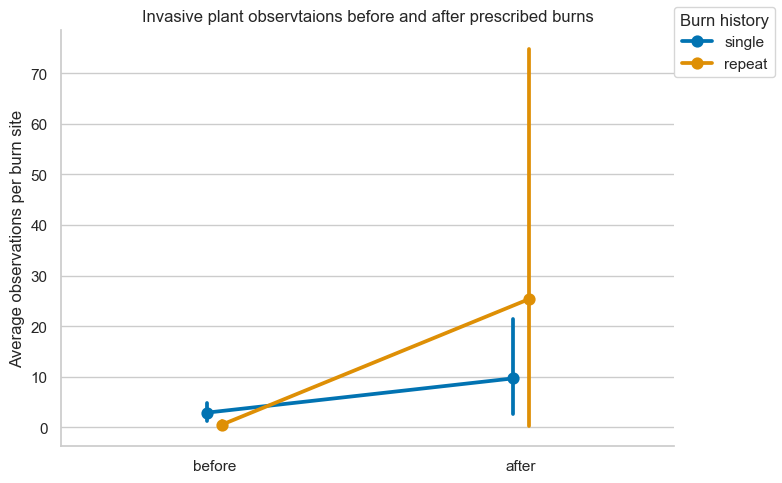

In [8]:
#Plot mean records per burn
g = sns.catplot(
    data=burn_counts_long,
    kind='point',
    x='timing',
    y='n_records',
    hue='burn_type',
    order=['before', 'after'],
    hue_order=['single', 'repeat'],
    dodge=True,
    aspect=1.4
)

g.set(
    title='Invasive plant observtaions before and after prescribed burns',
    xlabel='',
    ylabel='Average observations per burn site'
)

sns.move_legend(
    g,
    loc='upper right',
    title='Burn history',
    frameon=True
);

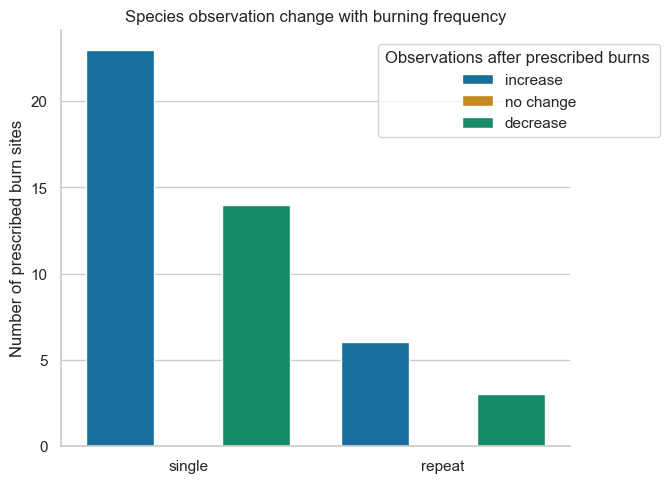

In [9]:
#Direction of change at each burn - Claude helped here
def change_direction(change):
    if change > 0: return 'increase'
    elif change < 0: return 'decrease'
    else: return 'no change'

burn_counts['direction'] = burn_counts['change'].map(change_direction)

#Table for number of burns in each direction
direction_table = (
    burn_counts
    .pivot_table(
        index='burn_type',
        columns='direction',
        values='burn_id',
        aggfunc='count', #Claude helped with aggfunc here
        fill_value=0
    )
    .reset_index()
)
direction_table

#Plot of how  burns saw invasive records change
g = sns.catplot(
    data=burn_counts,
    kind='count',
    x='burn_type',
    hue='direction',
    order=['single', 'repeat'],
    hue_order=['increase', 'no change', 'decrease'],
    aspect=1.2
)

g.set(
    title='Species observation change with burning frequency',
    xlabel='',
    ylabel='Number of prescribed burn sites'
)

sns.move_legend(
    g,
    loc='upper right',
    bbox_to_anchor=(0.95, 0.95),
    title='Observations after prescribed burns ',
    frameon=True
);